# Evasão × sucesso: as 4 variações

|            | **Leiden** (que perfis existem?) | **GNN GraphSAGE** (a vizinhança ajuda a prever?) |
|------------|------------------------|-------------------------------|
| **Gower**      | variação 1 | variação 2 |
| **Associação** | variação 3 | variação 4 |

O pipeline é um só. Entre as variações muda **só a distância** (linha) e **o método** (coluna). Todo o resto é igual nas quatro: dados, janelas, k, grafo e avaliação.

- **Dados:** UCI 697, só **Dropout × Graduate** (3.630 alunos). Os *Enrolled* ficam fora porque ainda não têm desfecho.
- **Grafo:** cada aluno é um vértice. A aresta i–j existe se um está entre os `K` mais parecidos do outro, nos dois sentidos (kNN mútuo). O desfecho **nunca** entra no grafo.
- **Janelas (Regra 1):** cada análise usa só o que já se sabia naquele momento.

In [1]:
# %pip install gower igraph leidenalg torch torch_geometric scikit-learn pandas matplotlib
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gower, igraph as ig, leidenalg as la
import torch, torch.nn.functional as F
from torch_geometric.nn.models import GraphSAGE, MLP
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, normalized_mutual_info_score as NMI
from scipy.stats import chi2_contingency

# ===== PARÂMETROS (iguais para as 4 variações) =====
K = 40                                     # vizinhos do kNN mútuo
JANELAS_RODAR = ["1_matricula", "3_fim_1sem"]
N_PERM = 1000                              # permutações do teste do Leiden
DOBRAS = 5                                 # validação cruzada da GNN
SEED = 42
torch.use_deterministic_algorithms(True); torch.set_num_threads(1)   # GNN reprodutível na mesma máquina

## 1. Dados e janelas

In [2]:
df = pd.read_csv("data.csv", sep=";")
NOMES = ["marital","app_mode","app_order","course","shift","prev_qual","prev_grade","nationality",
         "mother_qual","father_qual","mother_occ","father_occ","admission_grade","displaced",
         "special_needs","debtor","tuition_ok","gender","scholarship","age","international",
         "s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval",
         "s2_credited","s2_enrolled","s2_evaluations","s2_approved","s2_grade","s2_without_eval",
         "unemployment","inflation","gdp","target"]
df.columns = NOMES
df = df[df.target != "Enrolled"].reset_index(drop=True)      # 2 classes
y = (df.pop("target") == "Dropout").astype(int).values       # 1 = evadiu, 0 = formou
N = len(df)
print(f"{N} alunos | evasão geral = {y.mean():.1%}")

CAT_BASE = ["marital","app_mode","shift","prev_qual","nationality","mother_qual","father_qual",
            "mother_occ","father_occ","displaced","special_needs","gender","international"]
NUM_BASE = ["app_order","prev_grade","admission_grade","age"]
CAT_FIN  = CAT_BASE + ["debtor","tuition_ok","scholarship"]
NUM_S1   = ["s1_credited","s1_enrolled","s1_evaluations","s1_approved","s1_grade","s1_without_eval"]
NUM_S2   = [c.replace("s1_", "s2_") for c in NUM_S1]
JANELAS = {                                    # (categóricas, numéricas)
    "1_matricula":  (CAT_BASE, NUM_BASE),
    "2_financeiro": (CAT_FIN,  NUM_BASE),
    "3_fim_1sem":   (CAT_FIN,  NUM_BASE + NUM_S1),
    "4_fim_2sem":   (CAT_FIN,  NUM_BASE + NUM_S1 + NUM_S2),
}
# curso e macroeconomia ficam fora da distância; categorias com < 30 alunos viram "outros" (-1)
for c in CAT_FIN:
    vc = df[c].value_counts()
    df[c] = df[c].where(df[c].isin(vc[vc >= 30].index), -1)

3630 alunos | evasão geral = 39.1%


## 2. As duas distâncias (a variável das linhas)

- **Gower** (lib `gower`): numéricas entram como |a−b|/amplitude e categóricas como 0 (iguais) ou 1 (diferentes). Todas as variáveis têm o mesmo peso.
- **Associação** (preset `u_dep` do pacote R `manydist`): duas categorias da mesma variável ficam próximas se quem tem uma *se parece* com quem tem a outra nas demais variáveis. As numéricas são padronizadas e rotacionadas por PCA, e cada variável é dividida pela sua distância média. Como não existe lib Python, usamos a reimplementação do grupo, conferida contra o `manydist` 0.5.1 (correlação 1,000 em 500 alunos).

In [3]:
def dist_gower(cats, nums):
    X = pd.concat([df[cats].astype(str), df[nums].astype(float)], axis=1)
    return gower.gower_matrix(X, cat_features=[True] * len(cats) + [False] * len(nums))

def dist_associacao(cats, nums):
    D = np.zeros((N, N))
    # categóricas: perfil de cada categoria nas outras variáveis -> TVD entre perfis
    codes = [pd.Categorical(df[c]).codes for c in cats]
    Q = [c.max() + 1 for c in codes]; pos = np.cumsum([0] + Q); m = len(cats)
    Z = np.zeros((N, sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(N), pos[j] + c] = 1
    ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(Z.sum(0)[:, None], 1)
    for j, c in enumerate(codes):
        Pj = P[pos[j]:pos[j + 1]]
        delta = np.abs(Pj[:, None, :] - Pj[None, :, :]).sum(-1) / (2 * (m - 1))
        f = np.bincount(c, minlength=Q[j]) / N
        media = f @ delta @ f
        if media > 0: D += delta[c[:, None], c[None, :]] / media      # comensurável
    # numéricas: padroniza + PCA completo, cada componente dividido pela sua distância média
    X = df[nums].to_numpy(float); X = (X - X.mean(0)) / X.std(0, ddof=1)
    X = X @ np.linalg.svd(X, full_matrices=False)[2].T
    for k in range(X.shape[1]):
        dk = np.abs(X[:, k, None] - X[None, :, k]); D += dk / dk.mean()
    return D.astype(np.float32)

DISTANCIAS = {"Gower": dist_gower, "Associação": dist_associacao}

## 3. Grafo: kNN mútuo (igual para as duas distâncias)
Peso da aresta = semelhança = 1 − d / d_max. A divisão por d_max serve porque a distância por associação não fica entre 0 e 1.

In [4]:
def knn_mutuo(D, k=K):
    Dm = np.round(D, 6); np.fill_diagonal(Dm, np.inf)       # arredonda: empates exatos em qualquer máquina
    viz = np.argsort(Dm, axis=1, kind="stable")[:, :k]    # empate desfeito pelo índice do aluno
    A = np.zeros((N, N), bool); A[np.repeat(np.arange(N), k), viz.ravel()] = True
    i, j = np.where(np.triu(A & A.T, 1))
    return i, j, np.maximum(1 - D[i, j] / D.max(), 1e-3)

## 4. Os dois métodos (a variável das colunas)

**Leiden:** encontra comunidades sem olhar o desfecho. Depois perguntamos se as comunidades têm taxas de evasão diferentes, usando o **V de Cramér** entre comunidade e desfecho. Para saber se isso é real ou acaso, comparamos com `N_PERM` embaralhamentos do desfecho, mantendo o grafo fixo. Na análise só entram comunidades com pelo menos 30 alunos.

**GNN:** GraphSAGE (2 camadas, `torch_geometric`) contra um **MLP com a mesma arquitetura e sem arestas**. A diferença entre os dois responde se a vizinhança ajuda. A regressão logística entra como referência. Usamos validação cruzada estratificada com 5 dobras, e o rótulo da dobra de teste fica escondido. O grafo e os atributos de todos os alunos são visíveis (modo transdutivo, padrão em classificação de nós), mas nenhum rótulo de teste entra no treino.

In [5]:
def cramer_v(memb, yy):
    T = pd.crosstab(memb, yy).values
    return np.sqrt(chi2_contingency(T, correction=False)[0] / (T.sum() * (min(T.shape) - 1)))

def roda_leiden(i, j, w):
    g = ig.Graph(n=N, edges=list(zip(i, j))); g.es["weight"] = w
    part = la.find_partition(g, la.ModularityVertexPartition, weights="weight", seed=0)
    memb = np.array(part.membership)
    grandes = np.isin(memb, np.where(np.bincount(memb) >= 30)[0])     # comunidades >= 30 alunos
    mm, yy = memb[grandes], y[grandes]
    v = cramer_v(mm, yy)
    rs = np.random.default_rng(SEED)
    nulo = np.array([cramer_v(mm, rs.permutation(yy)) for _ in range(N_PERM)])
    comp = (pd.DataFrame({"comunidade": mm, "evadiu": yy}).groupby("comunidade")
              .agg(alunos=("evadiu", "size"), evasao=("evadiu", "mean"))
              .sort_values("evasao", ascending=False))
    return dict(memb=memb, comp=comp, modularidade=part.modularity, comunidades=len(comp),
                cobertura=grandes.mean(), V=v, V_max_nulo=nulo.max(),
                p=(1 + (nulo >= v).sum()) / (1 + N_PERM), NMI=NMI(mm, yy))

In [6]:
def atributos(cats, nums):
    oh = pd.get_dummies(df[cats].astype(str), dtype=np.float32).values
    num = df[nums].to_numpy(np.float32); num = (num - num.mean(0)) / num.std(0)
    return torch.tensor(np.hstack([oh, num]))

def treina(model, X, ei, tr, va, epocas=300, paciencia=30):
    yt = torch.tensor(y)
    peso = torch.tensor(len(tr) / (2 * np.bincount(y[tr])), dtype=torch.float32)   # compensa 39% evadiu x 61% formou
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    melhor, estado, sem = -1, None, 0
    for _ in range(epocas):
        model.train(); opt.zero_grad()
        F.cross_entropy(model(X, ei)[tr], yt[tr], weight=peso).backward(); opt.step()
        model.eval()
        with torch.no_grad(): f = f1_score(y[va], model(X, ei)[va].argmax(1), average="macro")
        if f > melhor: melhor, estado, sem = f, {k: v.clone() for k, v in model.state_dict().items()}, 0
        elif (sem := sem + 1) >= paciencia: break
    model.load_state_dict(estado); model.eval()
    with torch.no_grad(): return F.softmax(model(X, ei), 1)[:, 1].numpy()     # P(evadiu)

class SemArestas(torch.nn.Module):          # MLP do PyG com a mesma assinatura da GNN
    def __init__(self, d): super().__init__(); self.m = MLP(in_channels=d, hidden_channels=64, out_channels=2, num_layers=2, dropout=0.5, norm=None)
    def forward(self, x, ei): return self.m(x)

def roda_gnn(i, j, cats, nums):
    X = atributos(cats, nums)
    ei = torch.tensor(np.vstack([np.r_[i, j], np.r_[j, i]]), dtype=torch.long)
    linhas = []
    for f, (trv, te) in enumerate(StratifiedKFold(DOBRAS, shuffle=True, random_state=SEED).split(X, y)):
        tr, va = train_test_split(trv, test_size=0.15, stratify=y[trv], random_state=f)
        modelos = {"GraphSAGE": GraphSAGE(X.shape[1], 64, num_layers=2, out_channels=2, dropout=0.5),
                   "MLP (sem arestas)": SemArestas(X.shape[1])}
        for nome, mod in modelos.items():
            torch.manual_seed(f); p = treina(mod, X, ei, tr, va)
            linhas.append(dict(modelo=nome, dobra=f, F1=f1_score(y[te], p[te] > .5, average="macro"), AUC=roc_auc_score(y[te], p[te])))
        Xn = X.numpy(); lr = LogisticRegression(max_iter=3000, class_weight="balanced").fit(Xn[trv], y[trv])
        p = lr.predict_proba(Xn[te])[:, 1]
        linhas.append(dict(modelo="Logística", dobra=f, F1=f1_score(y[te], p > .5, average="macro"), AUC=roc_auc_score(y[te], p)))
    return pd.DataFrame(linhas)

## 5. Rodar as 4 variações

In [7]:
RES = {}
for jan in JANELAS_RODAR:
    cats, nums = JANELAS[jan]
    for dist, fn in DISTANCIAS.items():
        D = fn(cats, nums); i, j, w = knn_mutuo(D)
        isolados = N - len(np.unique(np.r_[i, j]))
        RES[jan, dist, "Leiden"] = roda_leiden(i, j, w)
        RES[jan, dist, "GNN"] = roda_gnn(i, j, cats, nums)
        v = RES[jan, dist, "Leiden"]["V"]; t = RES[jan, dist, "GNN"]
        f1 = t[t.modelo == "GraphSAGE"].F1.mean()
        print(f"{jan:12s} {dist:10s} | arestas={len(i):6d} isolados={isolados:3d} | Leiden V={v:.3f} | F1 GNN={f1:.3f}")

1_matricula  Gower      | arestas= 39980 isolados=  3 | Leiden V=0.316 | F1 GNN=0.687


1_matricula  Associação | arestas= 41742 isolados= 13 | Leiden V=0.332 | F1 GNN=0.671


3_fim_1sem   Gower      | arestas= 37318 isolados=  6 | Leiden V=0.463 | F1 GNN=0.858


3_fim_1sem   Associação | arestas= 36564 isolados= 30 | Leiden V=0.576 | F1 GNN=0.860


## 6. A tabela 2×2

In [8]:
def celula_leiden(r): return f"V={r['V']:.2f} (nulo ≤{r['V_max_nulo']:.2f}, p={r['p']:.3f}) · {r['comunidades']} com. · evasão {r['comp'].evasao.min():.0%}–{r['comp'].evasao.max():.0%}"
def celula_gnn(t):
    w = t.pivot(index="dobra", columns="modelo", values="F1"); g = w["GraphSAGE"] - w["MLP (sem arestas)"]
    return f"F1 GNN {w['GraphSAGE'].mean():.3f} · MLP {w['MLP (sem arestas)'].mean():.3f} · Log {w['Logística'].mean():.3f} · ganho {g.mean():+.3f}±{g.std():.3f}"

for jan in JANELAS_RODAR:
    tab = pd.DataFrame({"Leiden (que perfis existem?)": {d: celula_leiden(RES[jan, d, "Leiden"]) for d in DISTANCIAS},
                        "GNN GraphSAGE (a vizinhança ajuda?)": {d: celula_gnn(RES[jan, d, "GNN"]) for d in DISTANCIAS}})
    print(f"\n=== Janela {jan} ==="); display(tab.style.set_properties(**{"white-space": "normal", "text-align": "left"}))


=== Janela 1_matricula ===


,Leiden (que perfis existem?),GNN GraphSAGE (a vizinhança ajuda?)
Gower,"V=0.32 (nulo ≤0.10, p=0.001) · 12 com. · evasão 19%–70%",F1 GNN 0.687 · MLP 0.680 · Log 0.678 · ganho +0.006±0.012
Associação,"V=0.33 (nulo ≤0.10, p=0.001) · 16 com. · evasão 19%–67%",F1 GNN 0.671 · MLP 0.681 · Log 0.678 · ganho -0.010±0.010



=== Janela 3_fim_1sem ===


,Leiden (que perfis existem?),GNN GraphSAGE (a vizinhança ajuda?)
Gower,"V=0.46 (nulo ≤0.09, p=0.001) · 11 com. · evasão 13%–83%",F1 GNN 0.858 · MLP 0.859 · Log 0.869 · ganho -0.000±0.009
Associação,"V=0.58 (nulo ≤0.12, p=0.001) · 18 com. · evasão 4%–96%",F1 GNN 0.860 · MLP 0.863 · Log 0.869 · ganho -0.003±0.011


In [9]:
# números brutos, para o relatório
leiden_tab = pd.DataFrame([{"janela": j, "distancia": d, **{k: v for k, v in r.items() if k not in ("memb", "comp")}}
                           for (j, d, m), r in RES.items() if m == "Leiden"]).round(3)
gnn_tab = (pd.concat([t.assign(janela=j, distancia=d) for (j, d, m), t in RES.items() if m == "GNN"])
             .groupby(["janela", "distancia", "modelo"])[["F1", "AUC"]].agg(["mean", "std"]).round(3))
leiden_tab.to_csv("resultados/leiden_resumo.csv", index=False); gnn_tab.to_csv("resultados/gnn_resumo.csv")
display(leiden_tab); display(gnn_tab)

,janela,distancia,modularidade,comunidades,cobertura,V,V_max_nulo,p,NMI
0,1_matricula,Gower,0.672,12,0.999,0.316,0.100,0.001,0.034
1,1_matricula,Associação,0.841,16,0.996,0.332,0.101,0.001,0.035
2,3_fim_1sem,Gower,0.644,11,0.997,0.463,0.091,0.001,0.077
3,3_fim_1sem,Associação,0.821,18,0.991,0.576,0.116,0.001,0.109


F1           AUC       
                                           mean    std   mean    std
janela      distancia  modelo                                       
1_matricula Associação GraphSAGE          0.671  0.020  0.732  0.019
                       Logística          0.678  0.021  0.736  0.016
                       MLP (sem arestas)  0.681  0.021  0.736  0.016
            Gower      GraphSAGE          0.687  0.014  0.735  0.014
                       Logística          0.678  0.021  0.736  0.016
                       MLP (sem arestas)  0.680  0.016  0.736  0.013
3_fim_1sem  Associação GraphSAGE          0.860  0.009  0.924  0.005
                       Logística          0.869  0.009  0.930  0.006
                       MLP (sem arestas)  0.863  0.011  0.927  0.011
            Gower      GraphSAGE          0.858  0.009  0.921  0.009
                       Logística          0.869  0.009  0.930  0.006
                       MLP (sem arestas)  0.859  0.016  0.925  0.012

## 7. Perfis: composição do desfecho por comunidade

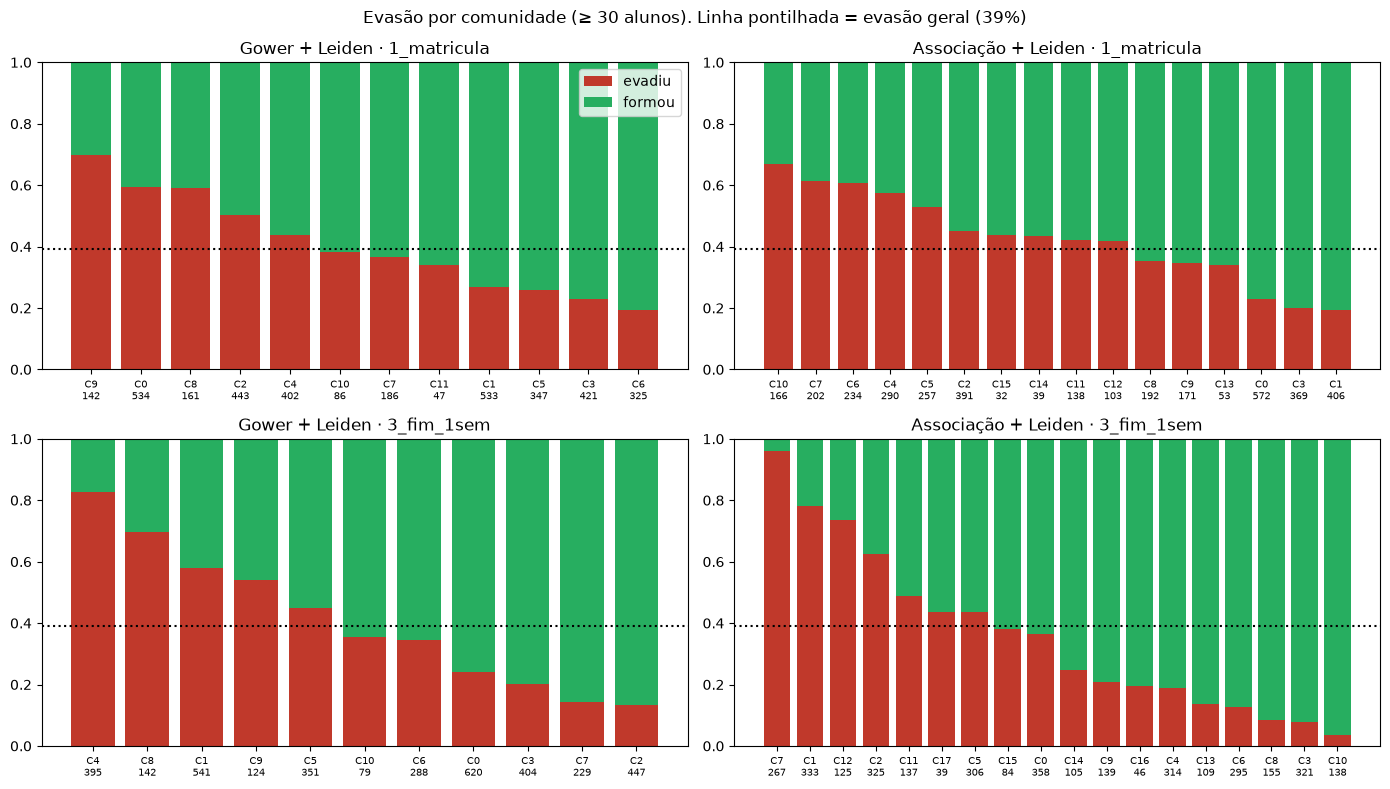

In [10]:
fig, axs = plt.subplots(len(JANELAS_RODAR), 2, figsize=(14, 4 * len(JANELAS_RODAR)), squeeze=False)
for a, jan in zip(axs, JANELAS_RODAR):
    for ax, dist in zip(a, DISTANCIAS):
        c = RES[jan, dist, "Leiden"]["comp"]; x = np.arange(len(c))
        ax.bar(x, c.evasao, color="#c0392b", label="evadiu"); ax.bar(x, 1 - c.evasao, bottom=c.evasao, color="#27ae60", label="formou")
        ax.axhline(y.mean(), ls=":", c="k"); ax.set_ylim(0, 1)
        ax.set_xticks(x, [f"C{i}\n{n}" for i, n in zip(c.index, c.alunos)], fontsize=7)
        ax.set_title(f"{dist} + Leiden · {jan}")
axs[0, 0].legend(loc="upper right")
fig.suptitle(f"Evasão por comunidade (≥ 30 alunos). Linha pontilhada = evasão geral ({y.mean():.0%})")
plt.tight_layout(); plt.savefig("resultados/leiden_composicao.png", dpi=150); plt.show()

In [11]:
# quem está nas comunidades de maior risco: numéricas em desvios-padrão da média geral;
# categorias presentes em >= 50% da comunidade e pelo menos 1,3x mais comuns que na base (×lift)
pd.set_option("display.max_colwidth", None)
def perfil(jan, dist, top=3):
    cats, nums = JANELAS[jan]; r = RES[jan, dist, "Leiden"]; z = (df[nums] - df[nums].mean()) / df[nums].std()
    linhas = []
    for c in r["comp"].index[:top]:
        m = r["memb"] == c; zc = z[m].mean(); zc = zc[zc.abs().sort_values(ascending=False).index[:3]]
        dom = []                                   # categorias com >= 50% na comunidade e lift >= 1,3 sobre a base
        for v in cats:
            for val, sh in df.loc[m, v].value_counts(normalize=True).items():
                lift = sh / (df[v] == val).mean()
                if sh >= 0.5 and lift >= 1.3: dom.append((f"{v}={val} ×{lift:.1f}", sh))
        dom = sorted(dom, key=lambda t: -t[1])[:3]
        linhas.append(dict(comunidade=c, alunos=m.sum(), evasao=f"{y[m].mean():.0%}",
                           numericas="; ".join(f"{k} {v:+.1f}dp" for k, v in zc.items()),
                           categorias="; ".join(f"{k} ({v:.0%})" for k, v in dom)))
    return pd.DataFrame(linhas)

for jan in JANELAS_RODAR:
    for dist in DISTANCIAS:
        print(f"\n--- {dist} · {jan}: 3 comunidades de maior evasão"); display(perfil(jan, dist))


--- Gower · 1_matricula: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,9,142,70%,age +0.7dp; admission_grade -0.4dp; app_order -0.1dp,mother_occ=0 ×21.1 (83%); mother_qual=34 ×22.3 (78%); father_qual=34 ×23.7 (71%)
1,0,534,59%,age +1.5dp; app_order -0.5dp; prev_grade -0.3dp,displaced=0 ×1.9 (86%); app_mode=39 ×4.2 (78%); mother_qual=37 ×3.0 (70%)
2,8,161,59%,age +0.9dp; app_order -0.5dp; admission_grade +0.4dp,app_mode=7 ×20.8 (76%); displaced=0 ×1.7 (76%); prev_qual=3 ×18.7 (63%)



--- Associação · 1_matricula: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,10,166,67%,age +0.5dp; admission_grade -0.3dp; app_order -0.1dp,mother_occ=0 ×19.4 (77%); mother_qual=34 ×19.5 (68%); father_qual=34 ×20.3 (61%)
1,7,202,61%,age +0.7dp; app_order -0.5dp; admission_grade +0.1dp,displaced=0 ×1.5 (66%)
2,6,234,61%,age +1.6dp; app_order -0.5dp; prev_grade -0.1dp,displaced=0 ×1.9 (84%); marital=2 ×8.2 (74%); app_mode=39 ×3.7 (68%)



--- Gower · 3_fim_1sem: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,4,395,83%,s1_grade -1.1dp; s1_approved -1.0dp; s1_enrolled -0.7dp,tuition_ok=0 ×4.8 (65%); gender=1 ×1.5 (51%)
1,8,142,70%,age +0.8dp; s1_grade -0.6dp; admission_grade -0.4dp,mother_occ=0 ×20.0 (79%); mother_qual=34 ×21.9 (77%); father_qual=34 ×23.5 (70%)
2,1,541,58%,age +1.5dp; app_order -0.5dp; s1_credited +0.3dp,displaced=0 ×1.9 (86%); mother_qual=37 ×3.2 (74%); father_qual=37 ×2.6 (73%)



--- Associação · 3_fim_1sem: 3 comunidades de maior evasão


,comunidade,alunos,evasao,numericas,categorias
0,7,267,96%,s1_grade -1.5dp; s1_approved -1.2dp; s1_evaluations -0.5dp,gender=1 ×1.6 (54%)
1,1,333,78%,s1_approved -0.4dp; age +0.3dp; s1_grade -0.3dp,debtor=1 ×8.7 (99%); displaced=0 ×1.3 (59%); tuition_ok=0 ×4.3 (58%)
2,12,125,74%,age +1.0dp; s1_grade -0.5dp; admission_grade -0.5dp,scholarship=0 ×1.3 (97%); mother_qual=34 ×21.7 (76%); father_qual=34 ×25.0 (75%)


## 8. Como ler

- **Leiden:** um V acima do maior valor obtido com o desfecho embaralhado (p = 0,001 é o menor possível com 1.000 permutações) quer dizer que os perfis são reais: as comunidades têm taxas de evasão diferentes, e o grafo foi montado **sem** o desfecho.
- **GNN:** se o ganho GNN − MLP fica perto de zero, a vizinhança não traz informação nova. Isso é esperado, porque as arestas saem dos mesmos atributos que o modelo já recebe. O objetivo do projeto é **descrever** perfis, não ganhar na previsão.
- **Gower × associação:** se as duas distâncias apontam o mesmo grupo de risco, o achado não depende da escolha da distância.
- Associação não é causa. O perfil de risco serve para oferecer apoio, nunca para rotular o aluno.